# Authors:
Juan Alejandro Ramon Ortega (s6470173)
Erika Saiz (s5880734)
Dániel Dávid (s6415997)

# Part I — Dimensionality Reduction

## 1. Load and inspect the dataset


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


wine = load_wine()

dimensions = pd.DataFrame(wine.data, columns=wine.feature_names)
wine_classes = pd.Series(wine.target, name="class")

print(dimensions.shape)               #(samples, features)
print(wine.target_names)              #the class names
print(wine_classes.value_counts())    #samples per class
print(dimensions.head())


(178, 13)
['class_0' 'class_1' 'class_2']
class
1    71
0    59
2    48
Name: count, dtype: int64
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39         

1. There are $178$ samples, as can be seen from the first value of the shape of $wine.data$. There are 178 rows, and reach row corresponds to one sample.
2. Each sample contains $13$ features, as can be seen from the second value of the shape of $wine.data$. There are 13 columns, and each column corresponds to one feature.
3. There are $3$ classes, which we can get by printing $wine.target\_names$.
4. No, the features are not measured on the same scale. For example, alcohol is measured by the percentage of the volume of ethanol in the wine, while proline is measured by miligrams per liter.


## 2. Standardize the features

In [3]:
#standardization
scaler = StandardScaler()
wine.data= scaler.fit_transform(wine.data)

Standardization is particularly important here because the features are measured on very different scales (for example, proline reaches values above 1000, while hue stays around 1). PCA looks for the directions of maximum variance, so without standardization the features with large variance would dominate the principal components, regardless of how informative they are.

## 3. Apply PCA

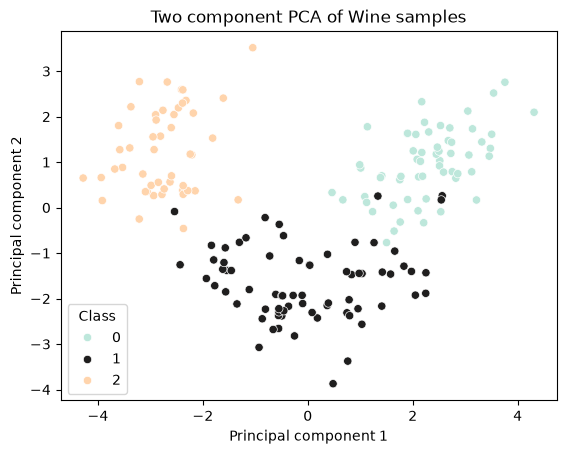

array([[ 3.31675081,  1.44346263],
       [ 2.20946492, -0.33339289],
       [ 2.51674015,  1.0311513 ],
       [ 3.75706561,  2.75637191],
       [ 1.00890849,  0.86983082],
       [ 3.05025392,  2.12240111],
       [ 2.44908967,  1.17485013],
       [ 2.05943687,  1.60896307],
       [ 2.5108743 ,  0.91807096],
       [ 2.75362819,  0.78943767],
       [ 3.47973668,  1.30233324],
       [ 1.7547529 ,  0.61197723],
       [ 2.11346234,  0.67570634],
       [ 3.45815682,  1.13062988],
       [ 4.31278391,  2.09597558],
       [ 2.3051882 ,  1.66255173],
       [ 2.17195527,  2.32730534],
       [ 1.89897118,  1.63136888],
       [ 3.54198508,  2.51834367],
       [ 2.0845222 ,  1.06113799],
       [ 3.12440254,  0.78689711],
       [ 1.08657007,  0.24174355],
       [ 2.53522408, -0.09184062],
       [ 1.64498834, -0.51627893],
       [ 1.76157587, -0.31714893],
       [ 0.9900791 ,  0.94066734],
       [ 1.77527763,  0.68617513],
       [ 1.23542396, -0.08980704],
       [ 2.18840633,

In [4]:
#PCA

def do_pca(data, components:int = 2, is_plot:bool = False, target = None, exp_variance:bool = False):
    pca_model = PCA(n_components=components, random_state= 100)
    pca_data= pca_model.fit(data)
    reduced_data= pca_data.transform(data)
    if is_plot:
        sns.scatterplot(x = reduced_data[:,0], y = reduced_data[:,1], hue = target, palette="icefire")
        plt.xlabel("Principal component 1")
        plt.ylabel("Principal component 2")
        plt.title("Two component PCA of Wine samples")
        plt.legend(title = "Class")
        plt.show()

    if exp_variance:
        return pca_data.explained_variance_ratio_
    return reduced_data
do_pca(wine.data, components= 2, is_plot= True, target = wine.target)

We made a function which performs PCA using sklearn's PCA method. We first fit the model with the wine data, and then transform it seperately. This is so we can get the attributes of both the PCA model, and also ge the dimension reduced data. Inside the function, we make the scatterplot of the individual samples which uses the first two principal components as the two axes, and colours them by the actual classes.


1. Yes, we can easily distinguish them, because there is clear separation between all three classes with very little overlapping, only a small amount between classes 0 and 1, and an even smaller amount between classes 1 and 2.
2. Class 2 is more easily separated from the others, while class 1 and class 0 have slightly more overlap.
3. Each point represents a projection from the transformed dataset $\bar{X}$ onto the two principal component’s eigenvectors.
4. Because we are only using two principal components, any fraction of the variance explained by only other components is lost. Essentially, it is only the variance in two dimensions.

## 4. Explained variance

The variance explained by the first two principal components are: [0.36198848 0.1920749 ]
Variance until explained up to and including 0th component: 0.3619884809992632
Variance until explained up to and including 1th component: 0.5540633835693526
Variance until explained up to and including 2th component: 0.6652996889318524
Variance until explained up to and including 3th component: 0.7359899907589927
Variance until explained up to and including 4th component: 0.8016229275554787
Variance until explained up to and including 5th component: 0.8509811607477044
Variance until explained up to and including 6th component: 0.8933679539739375
Variance until explained up to and including 7th component: 0.9201754434577262
Variance until explained up to and including 8th component: 0.9423969775056233
Variance until explained up to and including 9th component: 0.9616971684450641
Variance until explained up to and including 10th component: 0.9790655253449633
Variance until explained up to and inclu

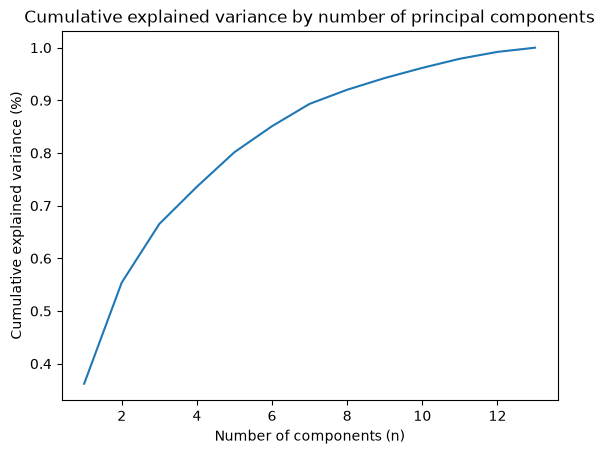

[np.float64(0.3619884809992632),
 np.float64(0.5540633835693526),
 np.float64(0.6652996889318524),
 np.float64(0.7359899907589927),
 np.float64(0.8016229275554787),
 np.float64(0.8509811607477044),
 np.float64(0.8933679539739375),
 np.float64(0.9201754434577262),
 np.float64(0.9423969775056233),
 np.float64(0.9616971684450641),
 np.float64(0.9790655253449633),
 np.float64(0.9920478511010054),
 np.float64(0.9999999999999999)]

In [5]:
print(f"The variance explained by the first two principal components are: {do_pca(wine.data, components= 2, exp_variance= True)}")
def explained_variance_sum(list_var, is_verbose:bool = False, is_plot:bool = False) -> list[float]:
    cumulative_sums = []
    sum = 0
    for i in range(len(list_var)):
        sum += list_var[i]
        cumulative_sums.append(sum)
        if is_verbose:
            print(f"Variance until explained up to and including {i}th component: {sum}")

    if is_plot:
        sns.lineplot(x = [i for i in range(1, 14)], y = cumulative_sums)
        plt.xlabel("Number of components (n)")
        plt.ylabel("Cumulative explained variance (%)")
        plt.title("Cumulative explained variance by number of principal components")
        plt.show()
    return cumulative_sums

explained_variance_sum(do_pca(wine.data, components= 13, exp_variance= True), is_verbose= True, is_plot= True)

1. The amount of variance explained by the first component is 36.2%, and the by the second 19.2%, which in total is 55.4%.
2. We made a function which takes in a list of explained variances (which the fitted PCA model already provides with the $explained\_variance\_ratio\_$ attribute), and stores and optionally prints the cumulative sums of the explained variances. Thus, we can see that we reach 80% explained variance with 5 components, 80.2% to be exact.
3. With the same function, wen can see that we reach 90% with 8 components, although 7 is almost there as well.
4. The main reasons for using dimensionality reduction despite the loss in explained variance include data visualization, as 2-3 dimensions are required to do so, data preprocessing, where we reduce the dimensionality to a manageable number, and the computational tractability. Not only does it decrease model complexity, it can actually increase generalization, due to only including the most relevant information from the data.

# Part II - Clustering

## 1. Apply K-Means

1. Since K-Means is an unsupervised learning algorithm it operates without beaing able to look at the actual wine labels. K-Means randomly initializes cluster centroids, and iteratively improves them by assigning the data points to the closest centroids and taking the average of those points to create the new centroids. At no point in this algorithm are true labels considered.

2. Classes are the true classifications of the samples, which is typically used in supervised learning. Clusters are similar data points that are grouped together by the machine learning algorithm, typically unsupervised, where we do not have access to actual classes.

## 2. Visualize the clusters using PCA

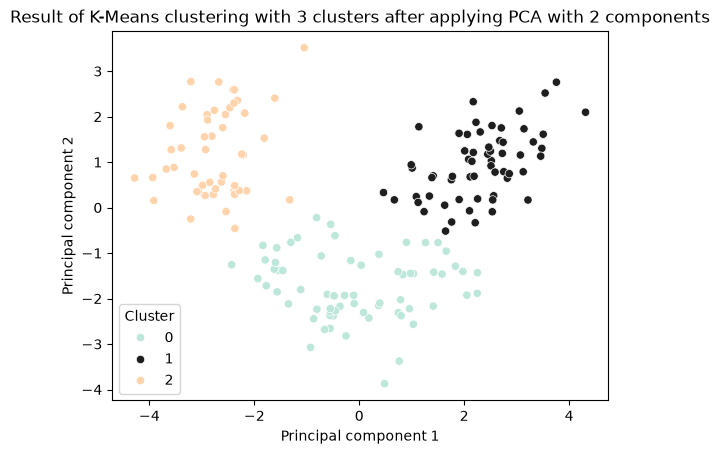

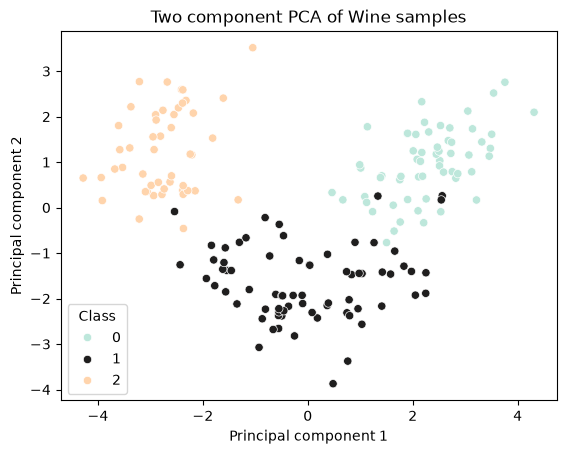

In [12]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

def do_kmeans(data, n_clusters:int = 8, is_plot:bool = False, is_cluster_silhouette:bool = False):
    kmeans = KMeans(n_clusters=n_clusters, random_state= 100).fit(data)
    wss = kmeans.inertia_
    clustered_data = kmeans.predict(data)
    if is_plot:
        if len(data[0]) != 2:
            raise Exception("Number of components has to be 2 to make a plot")
        sns.scatterplot(x = data[:,0], y = data[:,1], hue = clustered_data, palette="icefire")
        plt.xlabel("Principal component 1")
        plt.ylabel("Principal component 2")
        plt.title(f"Result of K-Means clustering with {n_clusters} clusters after applying PCA with 2 components")
        plt.legend(title = "Cluster")
        plt.show()
        
    if is_cluster_silhouette:
        sample_silhouette_values = silhouette_samples(data, clustered_data)
        cluster_silhouette_values = []
        for i in range(n_clusters):
            ith_cluster_silhouette_values = sample_silhouette_values[clustered_data == i]
            cluster_silhouette_values.append(np.mean(ith_cluster_silhouette_values))
        return wss, silhouette_score(data, clustered_data), sorted(cluster_silhouette_values)
    return wss, silhouette_score(data, clustered_data)

do_kmeans(do_pca(wine.data, 2), n_clusters= 3, is_plot= True)
original_wine_pca = do_pca(wine.data, components= 2, is_plot= True, target = wine.target)


1. In our plot we can see three clusters, since we selected $k=3$ for K-Means; the points in their respective clusters are close together, and there are fairly defined boundaries between the clusters. We also coloured them to make it easier to see in the plot.
2. No, the clusters look quite spread.
3. Yes, the clusters are very similar to the actual plot of the wine classes, as we can see above. The only difference is that the clustering cannot account for the datapoints which were overlapping in the classes, instead assigning them to the cluster that they are closest to.


## 3. Experiment with a different number of clusters

In [15]:
def compare_kmeans(min_n_clusters,max_n_clusters, is_elbow_plot:bool = False, is_combined_plot:bool = False, is_verbose:bool = False):
    wss_scores = []
    sihlouette_scores = []
    for i in range(min_n_clusters, max_n_clusters + 1):
        curr_score = do_kmeans(do_pca(wine.data, 2), n_clusters= i)
        wss_scores.append(curr_score[0])
        sihlouette_scores.append(curr_score[1])
        if is_verbose:
            print(curr_score)
    if is_elbow_plot:
        sns.lineplot(x = [i for i in range(min_n_clusters, max_n_clusters + 1)], y = wss_scores)
        plt.xlabel("Number of clusters (k)")
        plt.ylabel("Within Cluster Sum of Squared Errors")
        plt.title("Elbow plot for K-Means WSS")
        plt.show()
    if is_combined_plot:
        fig, ax1 = plt.subplots()
        ax2 = ax1.twinx()
        sns.lineplot(x = [i for i in range(min_n_clusters, max_n_clusters + 1)], y = wss_scores, ax= ax1, color = "blue", label = "WSS")
        sns.lineplot(x = [i for i in range(min_n_clusters, max_n_clusters + 1)], y = sihlouette_scores, ax= ax2, color = "green", label = "Silhouette coefficient")
        ax2.set_ylim(-1,1)
        ax1.set_xlabel("Number of clusters (k)")
        ax1.set_ylabel("Within Cluster Sum of Squared Errors")
        ax2.set_ylabel("Silhouette coefficient")
        plt.legend()
        ax1.legend(loc='upper left')
        plt.title("Elbow plot for K-Means WSS and Silhouette coefficients")
        plt.show()

    return wss_scores, sihlouette_scores

results = compare_kmeans(2, 8)
for i in range(len(results[0])):
    print(f"WSS with {i + 2} clusters: {results[0][i]}")
for j in range(len(results[1])):
    print(f"Silhoette-coefficient with {j + 2} clusters: {results[1][j]}")

WSS with 2 clusters: 628.7883507554765
WSS with 3 clusters: 259.8077220498024
WSS with 4 clusters: 201.7882856858293
WSS with 5 clusters: 169.12999742424253
WSS with 6 clusters: 123.01349501833543
WSS with 7 clusters: 104.74429542713867
WSS with 8 clusters: 91.68332329896323
Silhoette-coefficient with 2 clusters: 0.4649140908920152
Silhoette-coefficient with 3 clusters: 0.5615238075263915
Silhoette-coefficient with 4 clusters: 0.48567294206220224
Silhoette-coefficient with 5 clusters: 0.4618405906969398
Silhoette-coefficient with 6 clusters: 0.4309078483871919
Silhoette-coefficient with 7 clusters: 0.3874553307384578
Silhoette-coefficient with 8 clusters: 0.4243597896464072


1. As we can see from our outputs, the WSS decreases when k increases, but silhouette score does not increase, peaks at 3 clusters (same as amount of true classes).
2. k = 3 gives the strongest agreement with the known classes because it has the highest silhouette score, and as we have seen previously, compares very similarly with the known classes visually too.
3. We usually do not know the actual classes, so we should not rely on it. Also, clustering is about discovering patterns in the data. There might be important patterns which are different from the true classes, that we might miss if we hyperfixate on it. If we trained on the actual clusters, it would go against the point of unsupervised learning, where there is no point of reference, and it may fail to find paterns.


## 4. The Elbow Method

(628.7883507554765, 0.4649140908920152)
(259.8077220498024, 0.5615238075263915)
(201.7882856858293, 0.48567294206220224)
(169.12999742424253, 0.4618405906969398)
(123.01349501833543, 0.4309078483871919)
(104.74429542713867, 0.3874553307384578)
(91.68332329896323, 0.4243597896464072)


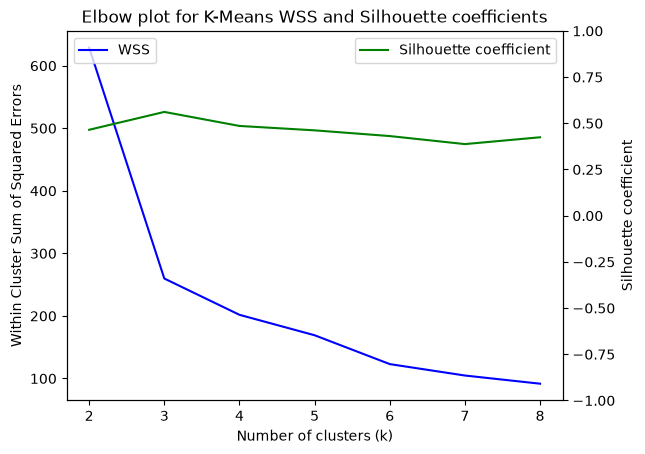

(259.8077220498024, 0.5615238075263915, [np.float64(0.44951299286014973), np.float64(0.6191660970520857), np.float64(0.6452086184700057)])
(201.7882856858293, 0.48567294206220224, [np.float64(0.3212190102403934), np.float64(0.4936567783797639), np.float64(0.5338361526317423), np.float64(0.5950430228881513)])
(169.12999742424253, 0.4618405906969398, [np.float64(0.2910281811032579), np.float64(0.44769063764329214), np.float64(0.4496786130996466), np.float64(0.49023804810409605), np.float64(0.5882350398877808)])
(91.68332329896323, 0.4243597896464072, [np.float64(0.27800260372167385), np.float64(0.3477229059049563), np.float64(0.40729286054399916), np.float64(0.41845817567607047), np.float64(0.43645893096392824), np.float64(0.4520777500631884), np.float64(0.49389749600446475), np.float64(0.5268447193303302)])


In [16]:
compare_kmeans(2, 8, is_combined_plot= True, is_verbose= True)
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 3, is_cluster_silhouette= True))
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 4, is_cluster_silhouette= True))
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 5, is_cluster_silhouette= True))
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 8, is_cluster_silhouette= True))


We believe that the elbow occurs at 3, since that is the number of classes. After printing it, we weren't sure at which k value it occurred, so we decided to look at the silhouette scores. With that, we got that the average of the 3 clusters was the best among the other possible k values since it had the highest score. Furthermore, we decided to investigate per cluster silhouette scores. In our function which performs K-Means, we added an option to aggregate the silhouette scores per cluster and return it. We can then see that for $k=3$, there is only one cluster below 0.5, while the others sit above 0.6, which is considered a great score. Comperatively, when going to and above $k=4$, most clusters retain a good score, but the added ones have terrible ones. Therefore, even though these extra clusters are driving WSS down, they are actually worse choices than $k=3$.

# Part 3: Neural Networks

## 1. Create a train/test split

In [9]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, log_loss, f1_score, confusion_matrix
from sklearn.neural_network import MLPClassifier
wine_data_train, wine_data_test, wine_target_train, wine_target_test = train_test_split(wine.data, wine.target,
                                                                                        test_size=0.2, random_state=100)

We chose a 20/80 split since this is a standard split size which is commonly used. Separation of the dataset is necessary, because we want to be able to evaluate the performance of our MLP on unseen, independent data, to judge generalization.

## 2. Standardizing the data


In [10]:
def mlp_grid_search(train_data, test_data, grid_search_criteria: str = "f1_weighted"):
    #setting up data
    scaler = StandardScaler()
    train_data, test_data = scaler.fit_transform(train_data), scaler.fit_transform(test_data)
    mlp_classifier = MLPClassifier()
    gridsearch = GridSearchCV(mlp_classifier, {'learning_rate_init': [0.001, 0.1, 1, 2], 'momentum' : [0.5, 0.9, 0.99, 0.999],
                                                        'learning_rate':['adaptive', 'invscaling'], 'early_stopping':[True],
                                                          'random_state':[100], 'hidden_layer_sizes' : [(10,),(10,10), (20,10)], 'solver':['sgd']}, scoring=grid_search_criteria)
    gridsearch = gridsearch.fit(train_data, wine_target_train)
    mlp_classifier = gridsearch.best_estimator_

    return mlp_classifier

def do_neural_network(train_data, test_data, train_target, test_target, is_cv: bool = False, is_matrix: bool = False, hidden_layer_sizes: tuple[int] = (20, ), early_stopping: bool = True):
    # setting up data
    scaler = StandardScaler()
    train_data, test_data = scaler.fit_transform(train_data), scaler.fit_transform(
        test_data)  # train and test data seperated, no leakage
    mlp_classifier = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, random_state=100, solver='sgd', early_stopping=early_stopping,
                                       learning_rate='adaptive', learning_rate_init=1, momentum=0.5).fit(train_data, train_target)

    if is_cv:
        cv_scores = cross_val_score(
            mlp_classifier, train_data, train_target, cv=5, scoring='f1_weighted')
        return np.mean(cv_scores), np.std(cv_scores)

   # predictions
    predictions_train = mlp_classifier.predict(train_data)
    predictions_test = mlp_classifier.predict(test_data)
    predictions_train_proba = mlp_classifier.predict_proba(train_data)
    predictions_test_proba = mlp_classifier.predict_proba(test_data)

    # accuracy
    train_accuracy = accuracy_score(train_target, predictions_train)
    test_accuracy = accuracy_score(test_target, predictions_test)

    # F1 Score
    train_f1_score = f1_score(
        train_target, predictions_train, average="weighted")
    test_f1_score = f1_score(
        test_target, predictions_test, average="weighted")

    # losses
    train_loss = log_loss(train_target, predictions_train_proba)
    test_loss = log_loss(test_target, predictions_test_proba)

    if is_matrix:
        train_matrix = confusion_matrix(
            train_target, predictions_train, labels=[0, 1, 2])
        test_matrix = confusion_matrix(
            test_target, predictions_test, labels=[0, 1, 2])
        print("Train confusion matrix")
        print(train_matrix)
        print("Test confusion matrix")
        print(test_matrix)

    return train_accuracy, test_accuracy, train_loss, test_loss, train_f1_score, test_f1_score

print(mlp_grid_search(wine_data_train, wine_data_test))
result = do_neural_network(wine_data_train, wine_data_test, wine_target_train,
    wine_target_test, is_matrix=True, hidden_layer_sizes=(10, ), early_stopping=True)
print(f"Training accuracy: {result[0]}, testing accuracy: {result[1]}, train log loss: {result[2]}, test log loss: {result[3]}, train F1 score: {result[4]}, test F1 score: {result[5]}")

MLPClassifier(early_stopping=True, hidden_layer_sizes=(10,),
              learning_rate='adaptive', learning_rate_init=1, momentum=0.5,
              random_state=100, solver='sgd')
Train confusion matrix
[[51  0  0]
 [ 0 55  1]
 [ 0  0 35]]
Test confusion matrix
[[ 8  0  0]
 [ 1 14  0]
 [ 0  0 13]]
Training accuracy: 0.9929577464788732, testing accuracy: 0.9722222222222222, train log loss: 0.18004186304553596, test log loss: 0.2981836523454905, train F1 score: 0.9929756179508213, test F1 score: 0.9725602884832093


We used sklearn's StandardScaler to both test and train data. It scales them seperately, thus there is no leakage. We used grid search to optimize our hyperparameters for the task. We selected stochastic gradient descent as the solver method because of its superior performance in the grid search, and to make plotting the losses easier later on. We searched a variety of learning rate initial values, momentum values, constant or adaptive learning and hidden layer sizes. The grid search found the best model to be the one with early_stopping=True, hidden_layer_sizes=(10,),learning_rate='adaptive', learning_rate_init=1, momentum=0.5, and solver='sgd'. From this point on, we used these hyperparameters unless the exercise asked us to change them.

Note: in the final code above, we removed the different solver methods from the grid search after finding 'sgd' as the best, so the grid search can be run faster, but we did actually run it with all methods.

1. Our neural network achieved a 0.972 accuracy score on the test set.
2. Our model classifies each wine classes quite well. Here you can see the confusion matrix:


$\begin{bmatrix}8&0&0\\1&14&0\\0&0&13 \end{bmatrix}$

Class 0: perfectly classified

Class 1: 1 misclassified as class 0, otherwise perfect

Class 2: perfectly classified

3. Feature scaling prevents features with larger ranges from skewing the errors, from which the weights are updated with backpropagation, since the magnitude of gradients depend on the scale of the features. Feature scaling also speeds up convergence of gradient descent.

4. The hidden layer performs the calculations that transform the input vectors into the output; more hidden layers allow more functions to be approximated, meaning that with hidden layers we are able to model more complex things. 

## 3. Experiment with network architectures

Early stopping = True

| layer             | (5,)                 | (10, )               | (20, )               | (50, )               | (20, 10)             | (50, 20)             |
|-------------------|----------------------|----------------------|----------------------|----------------------|----------------------|----------------------|
| training accuracy | 0.986   | 0.993 | 0.979   | 0.986 | 0.972  | 0.944 |
| testing accuracy  | 0.888   | 0.972   | 0.944   | 0.944   | 1.0   | 0.917   |
| train log loss    | 0.0139 | 0.180 | 0.078 | 0.083 | 0.005 | 0.261 |
| test log loss     | 0.305   | 0.298  | 0.156  | 0.162  | 0.097  | 0.226  |
| train F1 score    | 0.993   | 0.993 | 0.979   | 0.986| 0.971 | 0.944 |
| test F1 score     | 0.888   | 0.972   | 0.945   | 0.946   | 1.0   | 0.915

Early stopping = False

| layer             | (5,)                 | (10, )               | (20, )               | (50, )                | (20, 10)              | (50, 20)              |
|-------------------|----------------------|----------------------|----------------------|-----------------------|-----------------------|-----------------------|
| training accuracy | 1.0                  | 1.0                  | 1.0                  | 1.0                   | 1.0                   | 1.0                   |
| testing accuracy  | 0.917   | 0.944   | 0.972   | 0.944    | 0.944    | 0.972    |
| train log loss    | 0.006 | 0.002 | 0.0025 | 0.0025 | 0.0011 | 0.0009 |
| test log loss     | 0.183  | 0.158  | 0.138  | 0.224   | 0.183    | 0.173   |
| train F1 score    | 1.0                  | 1.0                  | 1.0                  | 1.0                   | 1.0                   | 1.0                   |
| test F1 score     | 0.916   | 0.945   | 0.972   | 0.945    | 0.945    | 0.972    |

 We made a loss plot function, which trains the models epoch by epoch to be able to store validation losses. The reason was to be able to analyze potential over-or underfitting. As we can see, the simple and more complex models both show no signifcant signs of overfitting, because both training and validation losses keep decreasing, and both of them reach a low value, so no underfitting. In combination with the obtained log loss values, it is safe to say that no architecture suffers from overfitting.

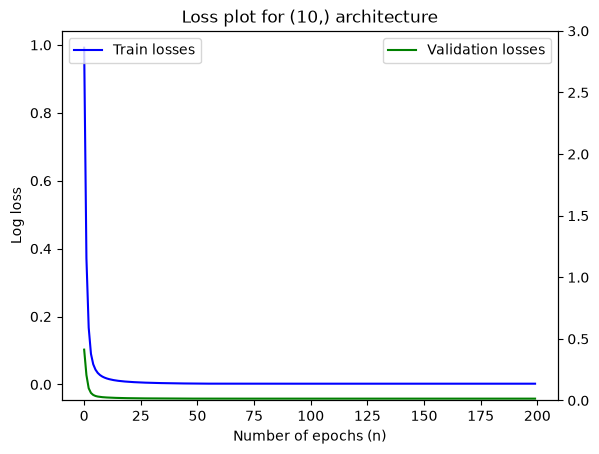

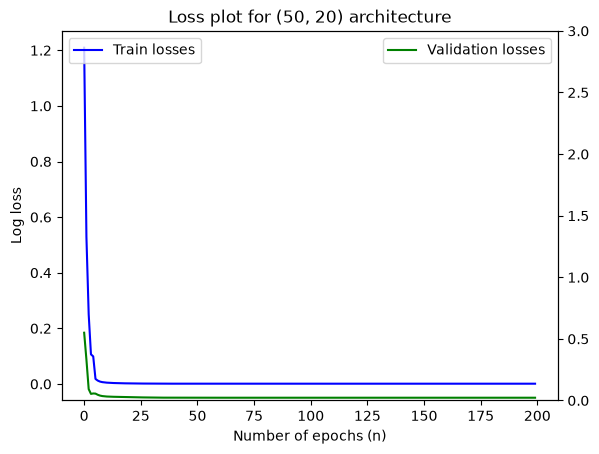

In [11]:
def do_loss_plot(data, target, hidden_layer_sizes, n_iter: int = 200):
    # setting up data
    scaler = StandardScaler()
    data = scaler.fit_transform(data)

    train_losses = []
    validation_losses = []
    curr_train_data, val_data, curr_train_target, val_target = train_test_split(
        data, target, test_size=0.1, random_state=100)
    mlp_classifier = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, random_state=100, solver='sgd',
                                   max_iter=1, warm_start=True, learning_rate='adaptive', learning_rate_init=1, momentum=0.5)
    for _ in range(n_iter):
        mlp_classifier = mlp_classifier.partial_fit(
            curr_train_data, curr_train_target, classes=np.unique(curr_train_target))
        train_losses.append(mlp_classifier.loss_)
        predictions_val = mlp_classifier.predict_proba(val_data)    
        cur_val_loss = log_loss(val_target, predictions_val)
        validation_losses.append(cur_val_loss)

    print_loss_curve(train_losses, validation_losses, hidden_layer_sizes)


def print_loss_curve(train_losses, validation_losses, hidden_layer_sizes):
    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()
    sns.lineplot(x=[i for i in range(len(train_losses))],
                 y=train_losses, ax=ax1, color="blue", label="Train losses")
    sns.lineplot(x=[i for i in range(len(train_losses))], y=validation_losses,
                 ax=ax2, color="green", label="Validation losses")
    ax2.set_ylim(0, 3)
    ax1.set_xlabel("Number of epochs (n)")
    ax1.set_ylabel("Log loss")
    plt.legend()
    ax1.legend(loc='upper left')
    plt.title(f"Loss plot for {hidden_layer_sizes} architecture")
    plt.show()

do_loss_plot(wine_data_train, wine_target_train, (10,))
do_loss_plot(wine_data_train, wine_target_train, (50,20))

1. Increasing the number of neurons will not always improve performance since more layers means a more complex model, and an overly complex model will overfit and generalize to a less degree, when the actual problem is simpler. We can see in our results that the later models with more neurons did not perform better than the simple ones on this simple dataset.

2. In our case, adding a second hidden layer did not meaningfully improve the results. This is because the classes are already nearly linearly separable. Therefore, there is no need to add additional layers, because they introduce unnecessary complexity and reduce generalization, leading to potential overfitting. 

3. As previously mentioned, when the network becomes overly complex, variance will increase, since small changes in the input will result in large changes in the output, which may cause overfitting to the training data. Even if the network performs perfectly on the training set, it will perform worse on the test set, or other independent sets.

4. An overly high model complexity can often lead to overfitting, as the models learns the noise of the training data, rather than the broader pattern, and thus fails to generalize. On the contrary, a model that is too simple can lead to underfitting. The ideal complexity of the model depends on the complexity of the data itself, as more linearly separable data will require simpler models for best performance. 


## 4. Comparing the neural network with previous models

Results for logistic regression and decision trees (we selected depth 5 as the best tree as the point of comparison), as well as our selected MLP with (10,) as its hidden layer:

| Model  | Depth |  Training accuracy | Testing accuracy  | Log loss train | Log loss test |
|--------|-------|--------------------|-------------------|----------------|---------------|
| Logistic Regression | NA | 1 | 0.944 | 0.037 | 0.125|
|Multi-Layer Perceptron | NA | 0.993 | 0.972 | 0.180 | 0.298 |
|Decision Tree| 1 | 0.725 | 0.583 | 0.631 | 0.801|
|Decision Tree | 2 | 0.978| 0.833 | 0.094 | 4.237|
|Decision Tree | 3 | 0.986 | 0.833 | 0.026 | 6|
|Decision Tree | 5 | 0.986 | 0.833 | 0.009 | 4.043|
|Decision Tree | 10 | 0.986 | 0.833 | 0.009 | 4.043|
|Decision Tree | 15 | 0.986 | 0.833 | 0.009 | 4.043|


1. Logistic regression and the MLP performed similarly, since they both achieved a nearly perfect accuracy and F1 score, without signs of strong overfitting. This is because they both work similarly in this case. Weights are learned with gradient descent, and modeling linear data is easy for both. There are differences in the architecture, such as logistic regression using the sigmoid function, and the MLP having a RELU activation function, but overall they are alike in this instance.

2. The decision tree performed differently compared to the other ones, because it had significantly worse accuracy and F1 score, as well as having stronger overfitting, as seen from the train and test log losses. The simple reason for this is the fact that the data is linearly separable and the tree model is non-linear, so a poorer performance with overfitting stemmed from complexity is shown. In general, decision trees are relatively prone to overfitting.

3. The neural network does not significantly outperform the simpler models since logistic regression performs almost exactly the same. This is because the data itself is relatively simple, and already almost linearly separable. The neural network adds unnecessary complexity that does not really help the model, but it is not as harmful as more complex versions of the MLP.

4. No, accuracy alone is not enough to decide which model is best, as it does not show whether the model is overfitting nor the possible presence of imbalanced classes having an effect on the model performance. It merely shows the classification success rate of the specific testing data, which, while an intuitive metric, hides a lot of information on the model's generalization capabilities and potential performance with external data.

5. Some advantages of neural networks are that they allow any function to be approximated, with enough neurons and layers. Therefore, if the classification question had significantly more complicated data, where relations between classes and features were non-linear, the neural network with the right hyperparameters would perform better than the logistic regression or the decision tree. The neural network is also more customizable, since by adjusting the number of neurons, training method, activation functions and other hyperparameters can be used for a large number of tasks, while the other models are more specialized.

6. Compared to simpler models, the adaptability of neural networks can also be a disadvantage: there are lots of hyperparameters to tune, while simpler models usually have less, and have better out-of-the box performance. Neural networks also typically take more time to train. They are less interpretable, compared to other models, like decision trees, since weights are arbitrary. As previously mentioned, overly complex models can lead to poor generalization and overfitting, so simpler models are preferred for simpler data.
